# Greedy focal stitching: AC 10 versus AC 40

`greedy_only_30mbp` · 300 diploid individuals · chr20, 1–31 Mb ·
AC ≤ 10 and AC ≤ 40 · exact focal intervals · 8 matching workers.
Three trials per mode and cutoff; the Full HMM baseline pools all six trials.
Greedy uses the full HMM within gaps.

In [1]:
import logging
import pathlib

import IPython.display as ipython_display

from ch5 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()
logger = logging.getLogger(__name__)

In [2]:
repository_dir = pathlib.Path.cwd()
config_path = {
    "benchmark_dir": repository_dir.parent
    / "tsinfer-match-eval/data/performance/greedy_only_30mbp",
    "output_dir": repository_dir / "data/ch5/stitching_pt5",
    "dataset": "tgp_chr20_n300_30mbp",
    "workers": None,
    "per_sample": {
        "worker_times_filename": "per_haplotype_worker_times.csv",
        "population_metadata": repository_dir
        / "data/general/populations/tgp_3202_pedigree.csv",
        "population_column": "population",
        "analysis_span_bp": [1000000, 31000000],
    },
    "correctness": {
        "mode": "from_reference",
        "repeat": 0,
        "baseline_partition_method": "greedy_ac10",
    },
    "methods": {
        "full_hmm": {"label": "Full HMM", "color": "#0072B2"},
        "greedy_ac10": {"label": "Greedy (AC 10)", "color": "#D55E00", "ac_cutoff": 10},
        "greedy_ac40": {"label": "Greedy (AC 40)", "color": "#009E73", "ac_cutoff": 40},
    },
}
config_path["base_dir"] = repository_dir
config = config_path
output_dir = nb_utils.resolve_path(config["output_dir"], repository_dir)
methods = list(config["methods"])
stitched_methods = [method for method in methods if method != "full_hmm"]
colors = {method: values["color"] for method, values in config["methods"].items()}
labels = {method: values["label"] for method, values in config["methods"].items()}
nb_plot.configure_notebook(
    {
        "figure.dpi": 120,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

In [3]:
if __name__ == "__main__":
    results = nb_utils.perf_pt5_load_results(config_path)
    runs = results.runs
    stages = results.stages
    comparisons = results.comparisons
    output_dir.mkdir(parents=True, exist_ok=True)
    comparisons.to_csv(output_dir / "haplotype_results.csv", index=False)
    results.fingerprints.to_csv(output_dir / "path_fingerprints.csv", index=False)
    reference_phases = nb_utils.reference_phases(runs, stages)
    reference_phases.to_csv(output_dir / "reference_phases.csv", index=False)
    runs["wall_ms_per_haplotype"] = 1000 * runs.wall_s / runs.matched_haplotypes
    runs["effective_cores"] = (runs.user_s + runs.system_s) / runs.wall_s
    runs["system_cpu_percentage"] = 100 * runs.system_s / (runs.user_s + runs.system_s)
    timing_summary = runs.groupby(["mode", "method"]).agg(
        mean_wall_s=("wall_s", "mean"),
        min_wall_s=("wall_s", "min"),
        max_wall_s=("wall_s", "max"),
        mean_wall_ms_per_haplotype=("wall_ms_per_haplotype", "mean"),
        mean_effective_cores=("effective_cores", "mean"),
        mean_system_cpu_percentage=("system_cpu_percentage", "mean"),
        maximum_trial_rss_bytes=("trial_peak_rss_bytes", "max"),
    )
    timing_summary.to_csv(output_dir / "timing_summary.csv")

## Correctness

One copy of each haplotype; paths and mutations agree across all modes and
repeats within each case. Each Greedy case uses its own focal mask.
The Full HMM switch-composition bar uses the AC 10 partition; its total
switch count is independent of the partition.
Parent agreement is averaged per haplotype within each named region.

**24 saved checks passed:** zero allele reconstruction errors and zero mismatches.

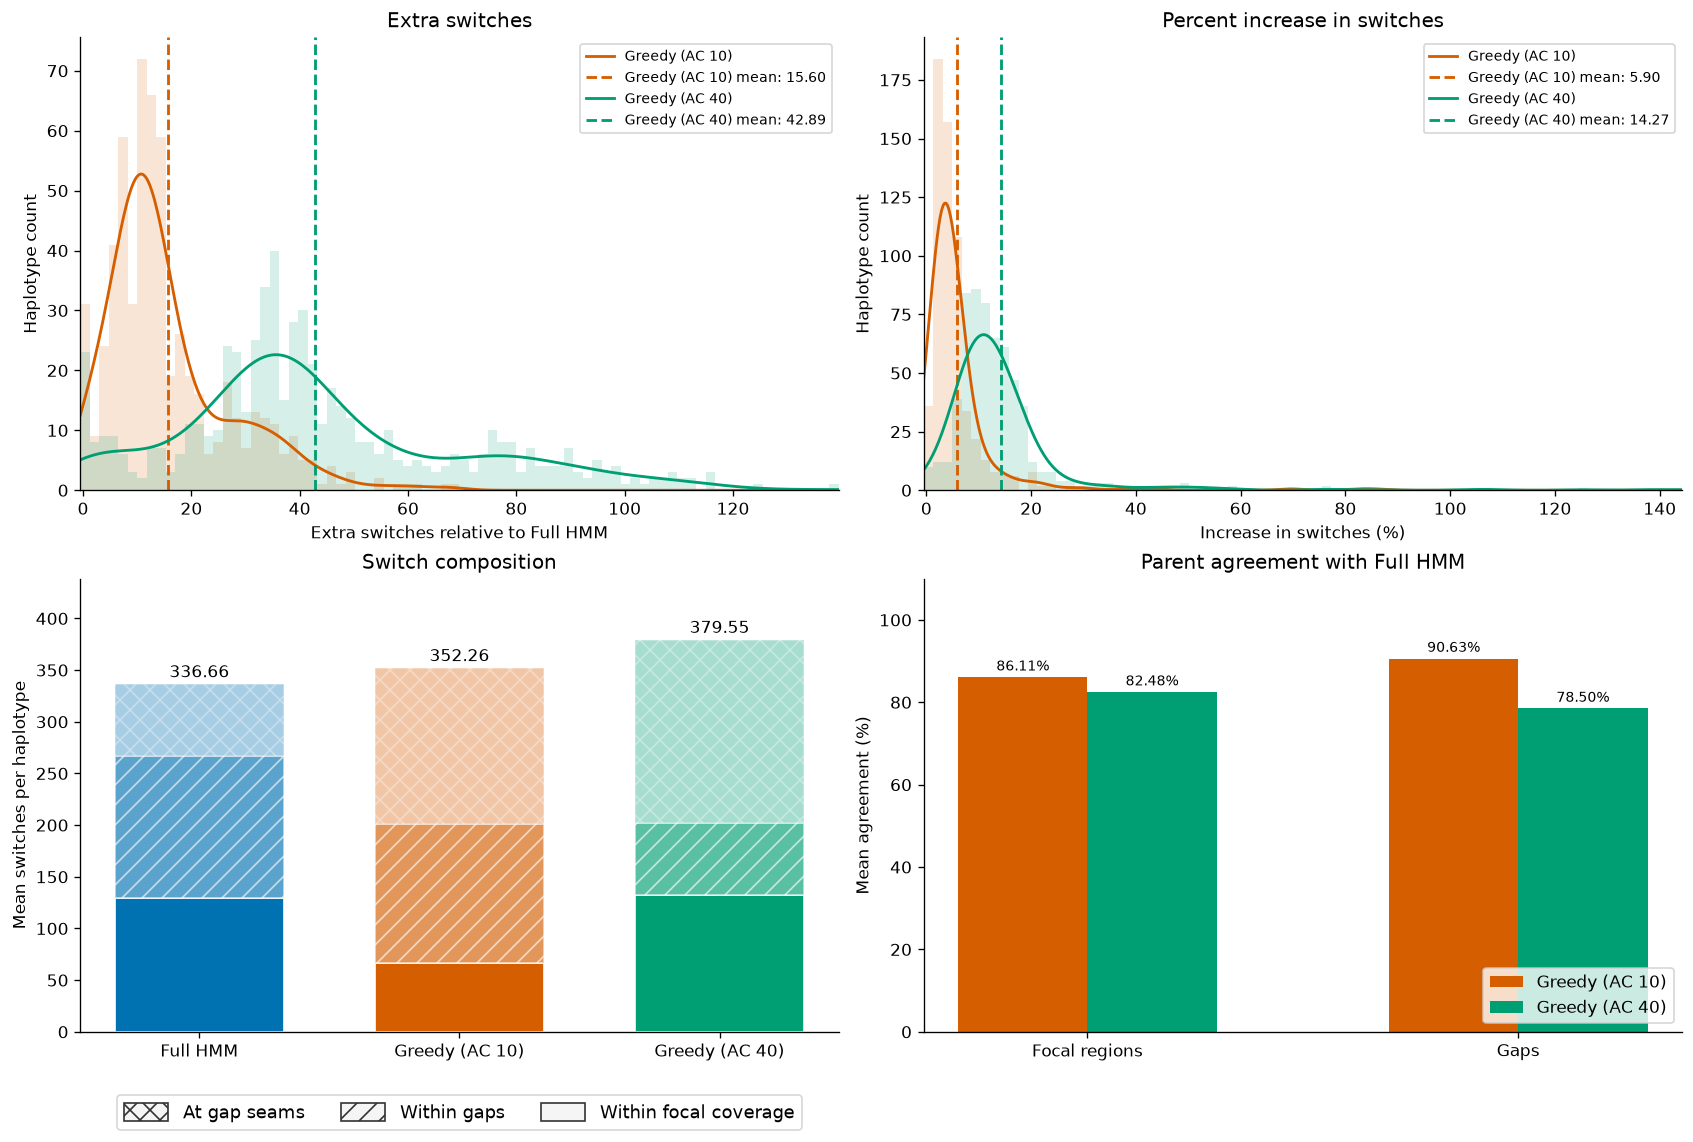

In [5]:
if __name__ == "__main__":
    message = f"**{len(results.quality)} saved checks passed:** zero allele reconstruction errors and zero mismatches."
    ipython_display.display(ipython_display.Markdown(message))
    fig, axes = nb_plot.panels(
        columns=2, rows=2, plot_panel_height=4.7, plot_panel_width=7
    )
    nb_plot.distribution(
        axes[0, 0],
        "num_extra_switches",
        "Extra switches relative to Full HMM",
        colors=colors,
        comparisons=comparisons,
        labels=labels,
        plot_histogram_alpha=0.16,
        plot_histogram_bins=80,
        plot_kde_bandwidth="scott",
        plot_kde_grid_size=512,
        plot_line_width=1.7,
        stitched_methods=stitched_methods,
    )
    nb_plot.plot_benchmark_correctness_panels(
        axes=axes,
        colors=colors,
        comparisons=comparisons,
        labels=labels,
        methods=methods,
        stitched_methods=stitched_methods,
        width=0.65,
        title="Switch composition",
        ylabel="Mean switches per haplotype",
        fontsize="small",
        title_2="Parent agreement with Full HMM",
        ylabel_2="Mean agreement (%)",
        ylim=(0, 110),
        baseline_partition_method=config["correctness"]["baseline_partition_method"],
    )
    nb_plot.benchmark_save_figure(
        fig, "correctness", output_dir=output_dir, plot_export_dpi=200
    )

## Performance

Bars show trial means; dots show individual trials (three per Greedy case,
six pooled across both cutoff passes for Full HMM).

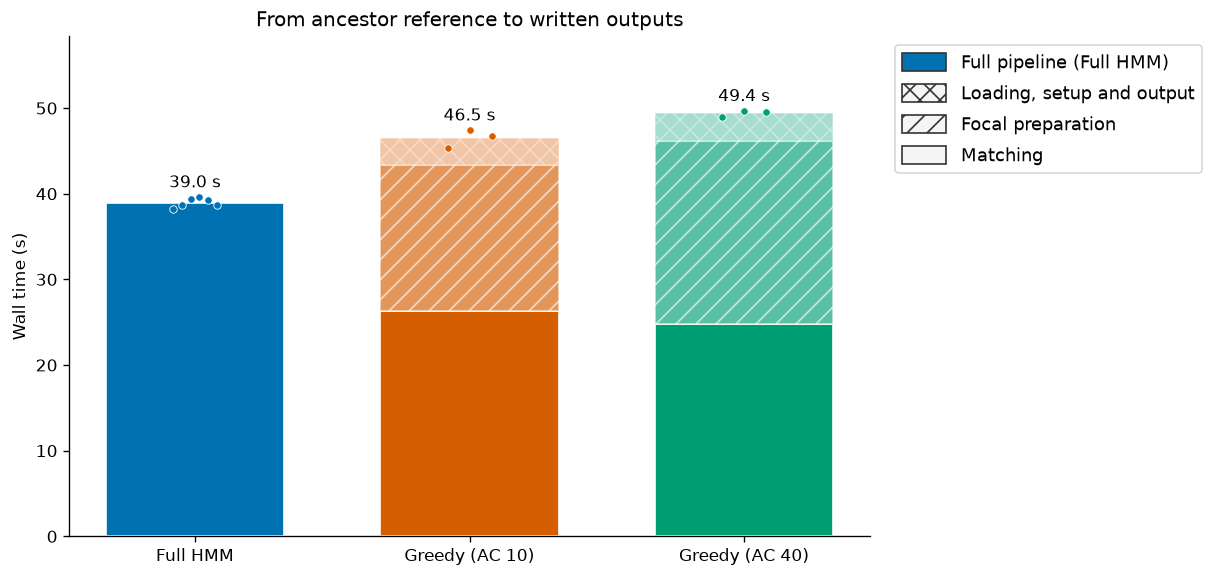

In [6]:
if __name__ == "__main__":
    fig, axes = nb_plot.panels(plot_panel_height=4.7, plot_panel_width=7)
    nb_plot.resize_figure(fig, figsize=(10, 4.7))
    ax = axes[0, 0]
    selected = runs.loc[runs["mode"].eq("from_reference")]
    nb_plot.plot_reference_wall_time(
        ax=ax,
        colors=colors,
        labels=labels,
        methods=methods,
        reference_phases=reference_phases,
        selected=selected,
        width=0.65,
        title="From ancestor reference to written outputs",
        ylabel="Wall time (s)",
    )
    nb_plot.phase_legend(
        ax,
        {
            "full_pipeline": {
                "label": "Full pipeline (Full HMM)",
                "legend_facecolor": "#0072B2",
                "alpha": 1,
                "hatch": "",
            },
            "matching": {"label": "Matching", "alpha": 1, "hatch": ""},
            "focal_preparation": {
                "label": "Focal preparation",
                "alpha": 0.65,
                "hatch": "//",
            },
            "other": {
                "label": "Loading, setup and output",
                "alpha": 0.35,
                "hatch": "xx",
            },
        },
        order=["full_pipeline", "other", "focal_preparation", "matching"],
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        plot_phase_legend_edgecolor="#333333",
        plot_phase_legend_facecolor="#F5F5F5",
        plot_phase_legend_font_size=11,
        plot_phase_legend_handleheight=1.2,
        plot_phase_legend_handlelength=2.4,
        plot_phase_legend_labelspacing=0.6,
    )
    nb_plot.benchmark_save_figure(
        fig, "from_reference_wall_time", output_dir=output_dir, plot_export_dpi=200
    )

Resident totals include worker setup and stitching. Wall time per haplotype
measures throughput at eight workers. Worker elapsed times include waits and
overlap across workers; Full HMM has no equivalent worker-stage breakdown.

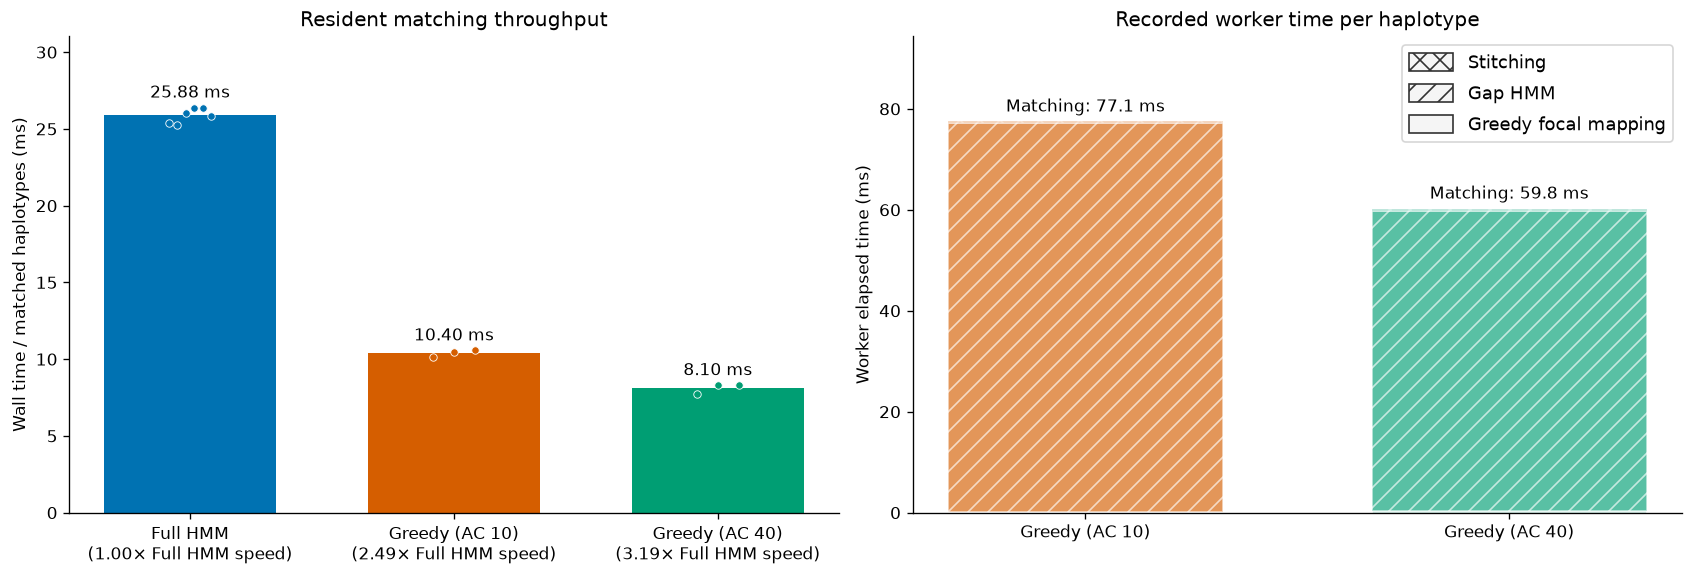

In [7]:
if __name__ == "__main__":
    resident = runs.loc[runs["mode"].eq("resident_match")]
    fig, axes = nb_plot.panels(columns=2, plot_panel_height=4.7, plot_panel_width=7)
    ax = axes[0, 0]
    full_mean = resident.loc[
        resident.method.eq("full_hmm"), "wall_ms_per_haplotype"
    ].mean()
    tick_labels = []
    ax = nb_plot.plot_matching_time_panels(
        axes=axes,
        colors=colors,
        full_mean=full_mean,
        labels=labels,
        methods=methods,
        output_dir=output_dir,
        resident=resident,
        stages=stages,
        stitched_methods=stitched_methods,
        tick_labels=tick_labels,
        width=0.65,
        title="Resident matching throughput",
        ylabel="Wall time / matched haplotypes (ms)",
        title_2="Recorded worker time per haplotype",
        ylabel_2="Worker elapsed time (ms)",
        ax=ax,
        worker_phases={
            "focal_match": {"label": "Greedy focal mapping", "alpha": 1, "hatch": ""},
            "gap_match": {"label": "Gap HMM", "alpha": 0.65, "hatch": "//"},
            "overhead": {"label": "Stitching", "alpha": 0.35, "hatch": "xx"},
        },
    )
    nb_plot.phase_legend(
        ax,
        {
            "focal_match": {"label": "Greedy focal mapping", "alpha": 1, "hatch": ""},
            "gap_match": {"label": "Gap HMM", "alpha": 0.65, "hatch": "//"},
            "overhead": {"label": "Stitching", "alpha": 0.35, "hatch": "xx"},
        },
        order=["overhead", "gap_match", "focal_match"],
        plot_phase_legend_edgecolor="#333333",
        plot_phase_legend_facecolor="#F5F5F5",
        plot_phase_legend_font_size=11,
        plot_phase_legend_handleheight=1.2,
        plot_phase_legend_handlelength=2.4,
        plot_phase_legend_labelspacing=0.6,
    )
    nb_plot.benchmark_save_figure(
        fig, "resident_matching", output_dir=output_dir, plot_export_dpi=200
    )

Memory uses sampled whole-trial peak RSS, including preparation and output.
CPU utilisation is process CPU time / resident wall time, including system time.

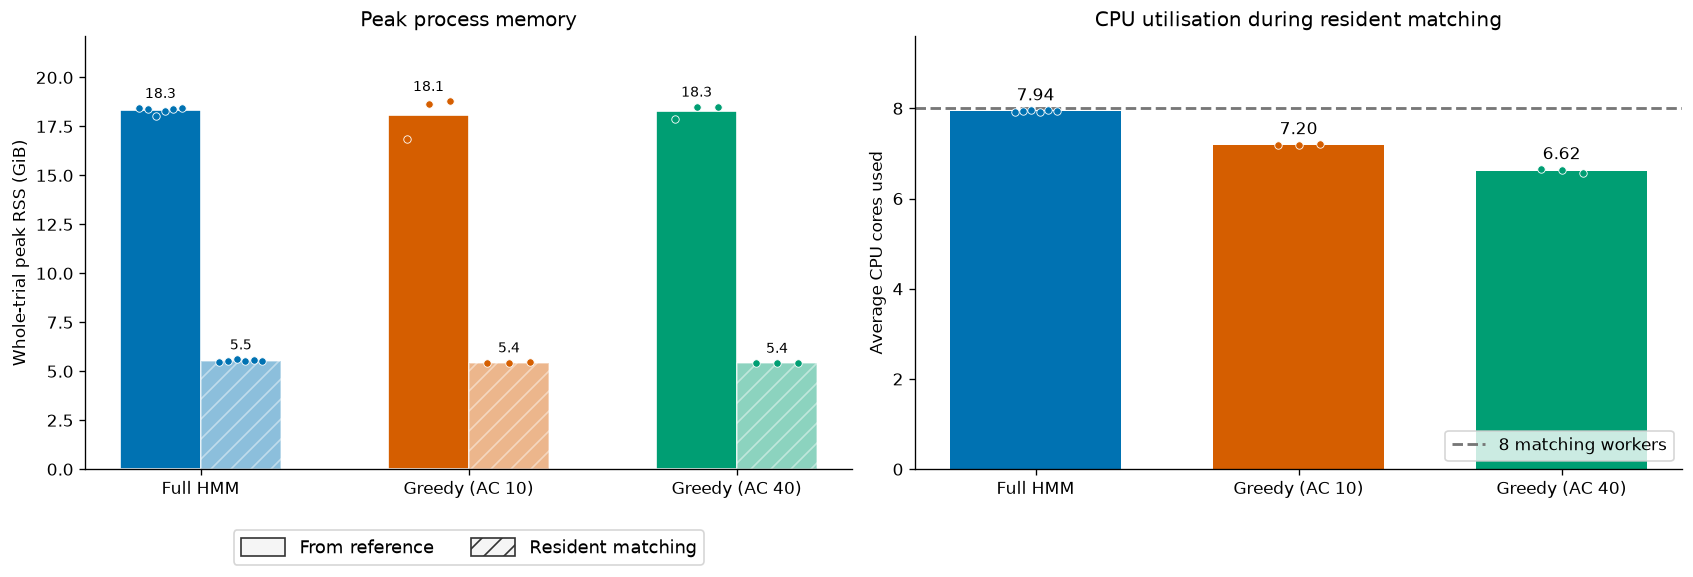

In [8]:
if __name__ == "__main__":
    fig, axes = nb_plot.panels(columns=2, plot_panel_height=4.7, plot_panel_width=7)
    ax = axes[0, 0]
    width = 0.3
    mode_count = len(
        {
            "from_reference": {"label": "From reference", "alpha": 1, "hatch": ""},
            "resident_match": {
                "label": "Resident matching",
                "alpha": 0.45,
                "hatch": "//",
            },
        }
    )
    nb_plot.plot_memory_parallelism_panels(
        axes=axes,
        colors=colors,
        labels=labels,
        methods=methods,
        mode_count=mode_count,
        resident=resident,
        runs=runs,
        width=width,
        fontsize="small",
        title="Peak process memory",
        ylabel="Whole-trial peak RSS (GiB)",
        width_1=0.65,
        color="#777777",
        linestyle="--",
        linewidth=1.7,
        title_2="CPU utilisation during resident matching",
        ylabel_2="Average CPU cores used",
        ax=ax,
    )
    nb_plot.benchmark_save_figure(
        fig, "memory_and_cpu", output_dir=output_dir, plot_export_dpi=200
    )

## Findings

Increasing the Greedy cutoff from 10 to 40 improves resident throughput and
expands focal coverage, but adds switches and lowers parent agreement with
Full HMM. Both Greedy cases remain slower from ancestor reference to written
outputs: the shorter matching phase does not offset focal preparation.
All saved quality checks pass, with identical paths and mutations across
modes/repeats within each case; this does not imply identical copying paths
between Greedy and Full HMM.

In [9]:
if __name__ == "__main__":
    summary = (
        timing_summary.xs("resident_match")
        .loc[methods, ["mean_wall_ms_per_haplotype"]]
        .copy()
    )
    baseline_ms = summary.loc["full_hmm", "mean_wall_ms_per_haplotype"]
    summary["speedup_over_full_hmm"] = baseline_ms / summary.mean_wall_ms_per_haplotype
    summary["from_reference_wall_s"] = timing_summary.xs("from_reference").mean_wall_s
    correctness_means = comparisons.groupby("method").agg(
        mean_extra_switches=("num_extra_switches", "mean"),
        mean_switch_increase_percentage=("switch_increase_percentage", "mean"),
    )
    summary = summary.join(correctness_means)
    summary["mean_focal_coverage_percentage"] = results.samples.groupby(
        "method"
    ).focal_coverage_percentage.mean()
    summary.to_csv(output_dir / "analysis_summary.csv")
    ipython_display.display(summary.rename(index=labels).round(2))

,mean_wall_ms_per_haplotype,speedup_over_full_hmm,from_reference_wall_s,mean_extra_switches,mean_switch_increase_percentage,mean_focal_coverage_percentage
method,,,,,,
Full HMM,25.88,1.00,38.96,NaN,NaN,NaN
Greedy (AC 10),10.40,2.49,46.49,15.60,5.90,73.04
Greedy (AC 40),8.10,3.19,49.42,42.89,14.27,85.59


## Per-sample data

Each point represents one diploid sample. Focal coverage is the mean physical
coverage of its two haplotypes over the analysed 1–31 Mb interval. Recorded
worker time sums all instrumented stages, averages across trials for each
haplotype, then averages the two haplotypes. Colours identify populations;
marginal histograms show sample counts using the same population colours.
Full HMM has no recorded worker-stage timings.

CHB samples have lower mean focal coverage and longer recorded worker times
at both cutoffs. The scatter shows an association between coverage and time;
population membership alone does not explain the variation within populations.

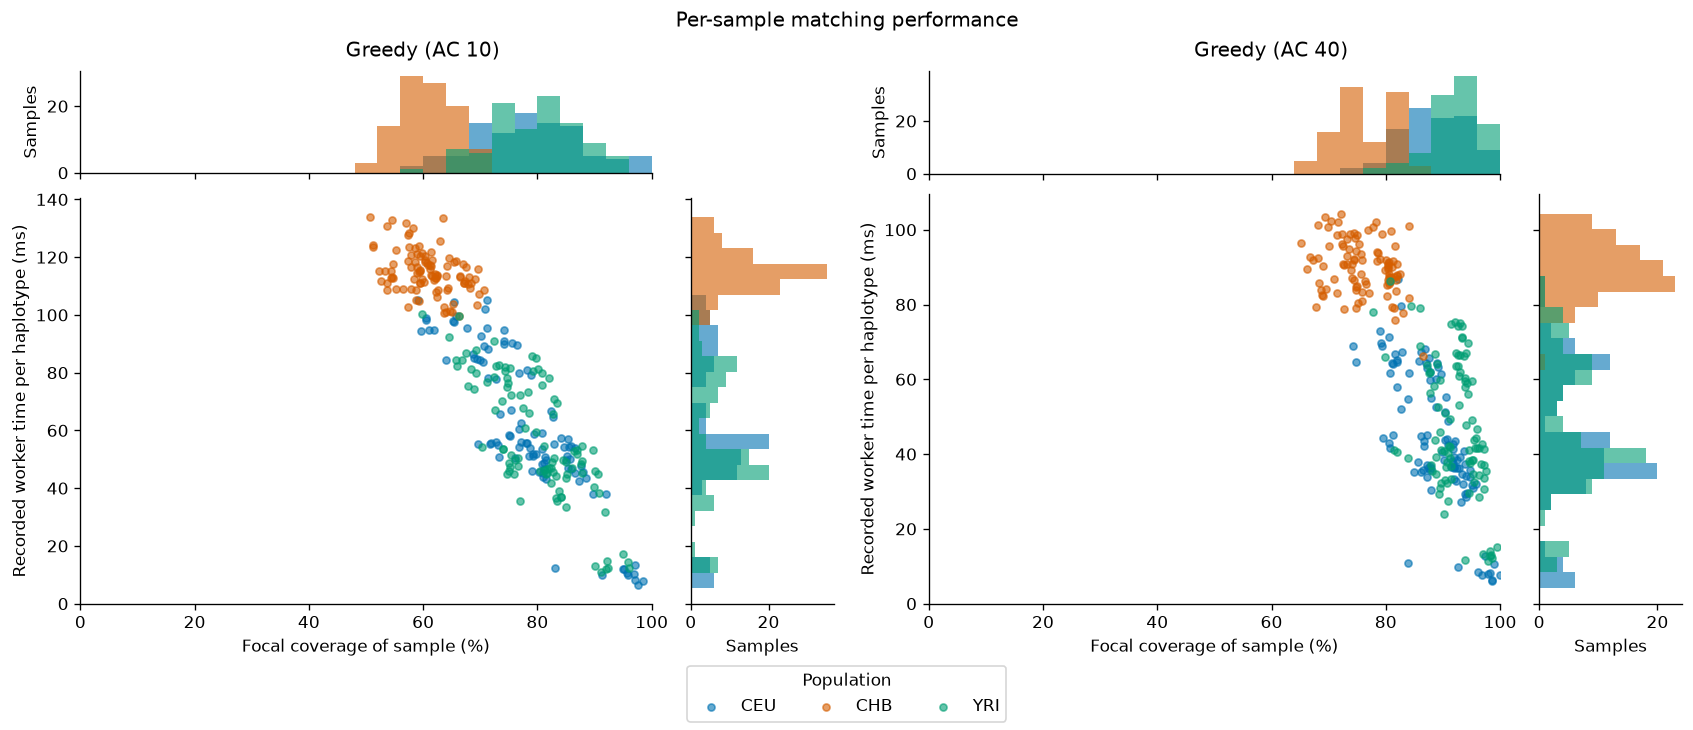

In [10]:
if __name__ == "__main__":
    sample_data = results.samples
    sample_data.to_csv(output_dir / "per_sample_matching_performance.csv", index=False)
    fig = nb_plot.plot_per_sample_data_2(
        labels=labels,
        sample_data=sample_data,
        stitched_methods=stitched_methods,
        figsize=(14, 6),
        s=18,
        alpha=0.6,
        xlabel="Focal coverage of sample (%)",
        ylabel="Recorded worker time per haplotype (ms)",
        xlim=(0, 100),
        ylim=(0, None),
        ylabel_2="Samples",
        xlabel_2="Samples",
        title="Population",
    )
    nb_plot.benchmark_save_figure(
        fig,
        "per_sample_matching_performance",
        output_dir=output_dir,
        plot_export_dpi=200,
    )